# 03 – Implied volatilities

This notebook computes the implied volatility of every out-of-the-money option, using the Black
model on the forward price. It also computes the implied volatilities of the bid and the ask, which
measure how uncertain each volatility is.

The output is the file `SPX_2026-10-26_1030_iv.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from functions import black_price, implied_vol

SNAPSHOT = "SPX_2026-10-26_1030"      # the market snapshot used in the whole project
DATA_DIR = "data"                     # folder with all input and output files

df = pd.read_csv(os.path.join(DATA_DIR, SNAPSHOT + "_clean.csv"))
print(df.shape)

(8997, 26)


## 1. The Black model (Black-76)

SPX options are European, so we can price them with the Black model written on the forward price
$F$. With strike $K$, time to expiry $T$, discount rate $r$ and volatility $\sigma$:

$$d_1 = \frac{\ln(F/K) + \frac{1}{2}\sigma^2 T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$$C = e^{-rT}\left(F\,N(d_1) - K\,N(d_2)\right), \qquad P = e^{-rT}\left(K\,N(-d_2) - F\,N(-d_1)\right)$$

where $N(\cdot)$ is the standard normal cumulative distribution function. The function
`black_price` is defined in `functions.py`. As a first test, an at-the-money call and put with
$F = K = 100$, $T = 1$, $r = 5\%$ and $\sigma = 20\%$ must have the same price, 7.5771.

In [2]:
print(black_price(100, 100, 1, 0.05, 0.20, "C"))
print(black_price(100, 100, 1, 0.05, 0.20, "P"))

7.57708214642728
7.57708214642728


## 2. Implied volatility with Brent's method

There is no closed formula that gives $\sigma$ from a price, so we solve

$$\text{BlackPrice}(F, K, T, r, \sigma) - \text{market price} = 0$$

with Brent's root-finding method (`brentq`), searching between 0.01% and 1000%. If no volatility in
this range reproduces the price (for example because the price breaks an arbitrage bound), the
function `implied_vol` in `functions.py` returns `NaN`.

In [3]:
iv_list = []
for _, row in df.iterrows():
    iv_list.append(implied_vol(row["mid"], row["F"], row["strike"], row["T"], row["r"], row["type"]))
df["iv"] = iv_list

print(df["iv"].notna().sum(), "solved,", df["iv"].isna().sum(), "not solved")
print(df["iv"].describe())

8997 solved, 0 not solved
count    8997.000000
mean        0.225952
std         0.124763
min         0.100238
25%         0.143194
50%         0.185256
75%         0.261921
max         1.000233
Name: iv, dtype: float64


### How fast Brent converges

For the first option of the file, we record every volatility tried by the solver and the price
error at each step. The error falls very quickly, so the solver needs only a few evaluations.

7 evaluations, implied vol = 0.141131


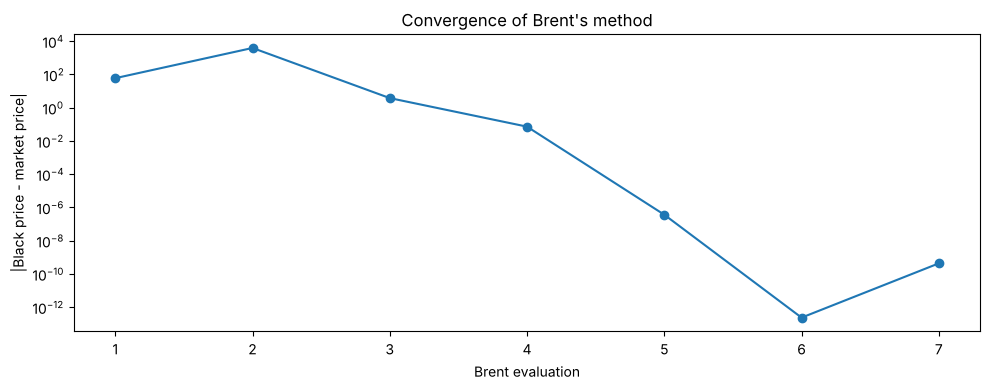

In [4]:
row = df.iloc[0]
tried = []

def difference(sigma):
    tried.append(sigma)
    return black_price(row["F"], row["strike"], row["T"], row["r"], sigma, row["type"]) - row["mid"]

iv = brentq(difference, 0.0001, 10)

errors = []
for s in tried:
    errors.append(abs(black_price(row["F"], row["strike"], row["T"], row["r"], s, row["type"]) - row["mid"]))

print(len(tried), "evaluations, implied vol =", round(iv, 6))

plt.figure(figsize=(10, 4))
plt.semilogy(range(1, len(errors) + 1), errors, marker="o")
plt.xlabel("Brent evaluation")
plt.ylabel("|Black price - market price|")
plt.title("Convergence of Brent's method")
plt.tight_layout()
plt.show()

### Price and vega

The option price always increases with volatility, so each price corresponds to exactly one
implied volatility. The slope of the price curve is the vega:

$$\text{vega} = e^{-rT} F\, \varphi(d_1)\sqrt{T},$$

where $\varphi$ is the standard normal density. Vega is largest at the money and small for options
far from the money. A small vega means that a small price error becomes a large volatility error,
which is why the implied volatilities of deep out-of-the-money options are less precise.

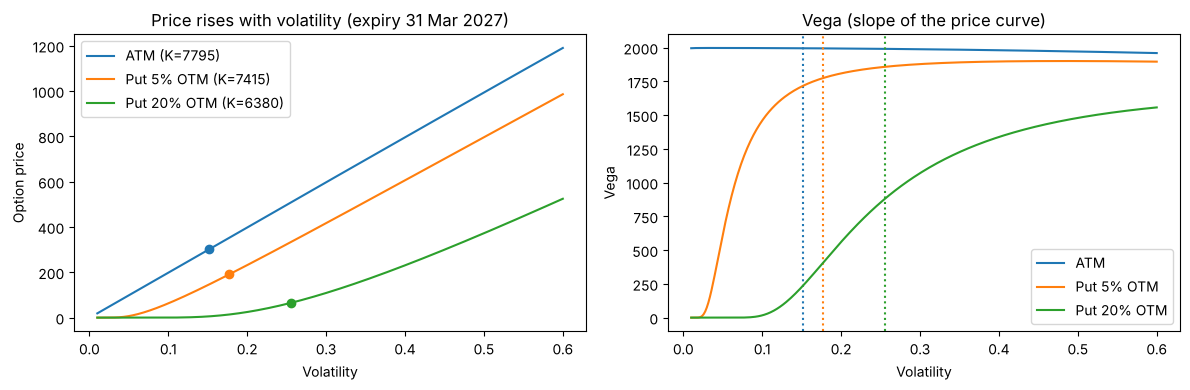

In [5]:
def vega(F, K, T, r, sigma):
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    return np.exp(-r * T) * F * norm.pdf(d1) * np.sqrt(T)

exp_df = df[df["expiry"] == "2027-03-31"]

chosen = {}
for label, target_k in [("ATM", 0.0), ("Put 5% OTM", -0.05), ("Put 20% OTM", -0.20)]:
    idx = (exp_df["k"] - target_k).abs().idxmin()        # option with k closest to the target
    chosen[label] = exp_df.loc[idx]

sigmas = np.linspace(0.01, 0.6, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for label, row in chosen.items():
    prices = [black_price(row["F"], row["strike"], row["T"], row["r"], s, row["type"]) for s in sigmas]
    vegas = [vega(row["F"], row["strike"], row["T"], row["r"], s) for s in sigmas]
    line, = ax1.plot(sigmas, prices, label=f"{label} (K={row['strike']:.0f})")
    ax1.plot(row["iv"], row["mid"], "o", color=line.get_color())          # market point
    ax2.plot(sigmas, vegas, label=label, color=line.get_color())
    ax2.axvline(row["iv"], linestyle=":", color=line.get_color())         # its implied vol

ax1.set_xlabel("Volatility")
ax1.set_ylabel("Option price")
ax1.set_title("Price rises with volatility (expiry 31 Mar 2027)")
ax1.legend()
ax2.set_xlabel("Volatility")
ax2.set_ylabel("Vega")
ax2.set_title("Vega (slope of the price curve)")
ax2.legend()
plt.tight_layout()
plt.show()

## 3. The volatility smile

For five expiries close to 1 month, 3 months, 6 months, 1 year and 2 years, we plot the implied
volatility against the log-moneyness. All expiries show the typical equity skew: volatility is much
higher for low strikes (puts) than for high strikes, and the skew is steeper for short expiries.

['2026-11-25', '2027-01-29', '2027-04-16', '2027-10-15', '2028-12-15']


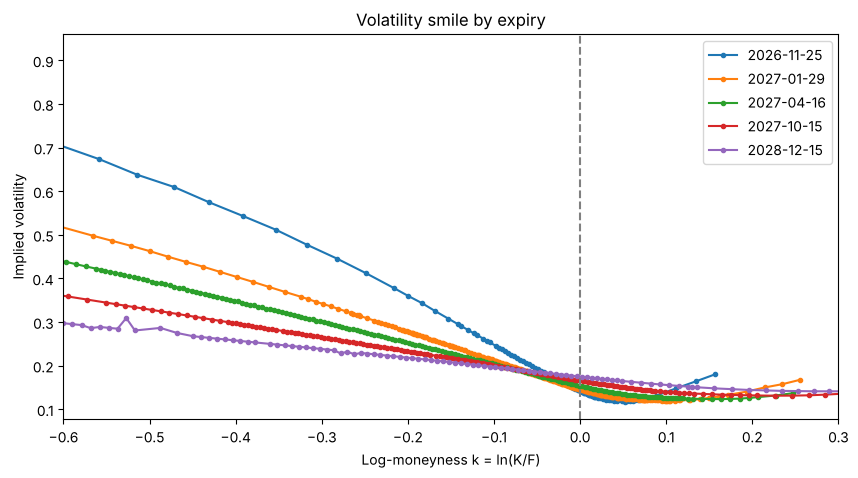

In [6]:
target_maturities = [1/12, 0.25, 0.5, 1, 2]
expiry_T = df.groupby("expiry")["T"].first()

selected = []
for target in target_maturities:
    selected.append((expiry_T - target).abs().idxmin())     # listed expiry closest to the target
print(selected)

plt.figure(figsize=(10, 5))
for exp in selected:
    sub = df[df["expiry"] == exp].sort_values("k")
    plt.plot(sub["k"], sub["iv"], marker=".", label=exp)
plt.axvline(0, color="gray", linestyle="--")
plt.xlim(-0.6, 0.3)
plt.xlabel("Log-moneyness k = ln(K/F)")
plt.ylabel("Implied volatility")
plt.title("Volatility smile by expiry")
plt.legend()
plt.show()

## 4. At-the-money term structure

For each expiry we take the option closest to the forward ($k$ closest to zero).

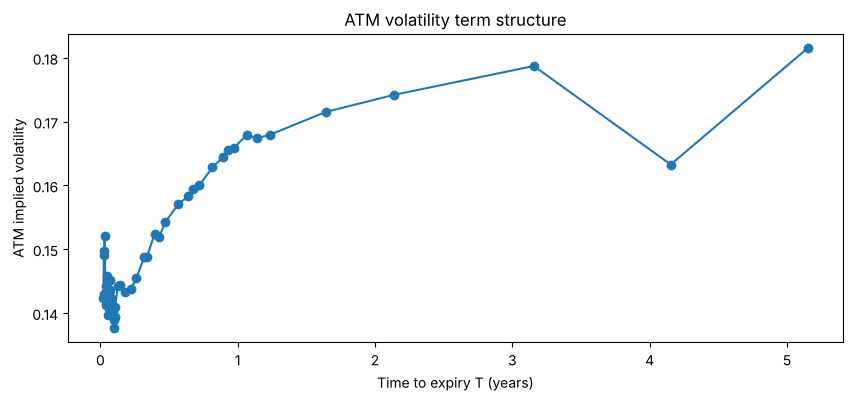

In [7]:
atm_T = []
atm_iv = []
for exp, sub in df.groupby("expiry"):
    idx = sub["k"].abs().idxmin()
    atm_T.append(sub.loc[idx, "T"])
    atm_iv.append(sub.loc[idx, "iv"])

plt.figure(figsize=(10, 4))
plt.plot(atm_T, atm_iv, marker="o")
plt.xlabel("Time to expiry T (years)")
plt.ylabel("ATM implied volatility")
plt.title("ATM volatility term structure")
plt.show()

## 5. Bid and ask volatilities

We repeat the calculation with the bid and the ask prices. The difference
`iv_spread = iv_ask - iv_bid` is the bid-ask spread measured in volatility. It tells how precisely
the market fixes each volatility, and in notebook 04 it is used as the weight of each quote in the
SVI calibration.

In [8]:
iv_bid_list = []
iv_ask_list = []
for _, row in df.iterrows():
    iv_bid_list.append(implied_vol(row["bid"], row["F"], row["strike"], row["T"], row["r"], row["type"]))
    iv_ask_list.append(implied_vol(row["ask"], row["F"], row["strike"], row["T"], row["r"], row["type"]))

df["iv_bid"] = iv_bid_list
df["iv_ask"] = iv_ask_list
df["iv_spread"] = df["iv_ask"] - df["iv_bid"]

print(df[["iv_bid", "iv_ask"]].isna().sum())
print(df["iv_spread"].describe())

iv_bid    0
iv_ask    0
dtype: int64
count    8997.000000
mean        0.002747
std         0.008183
min         0.000159
25%         0.000609
50%         0.000914
75%         0.001544
max         0.180553
Name: iv_spread, dtype: float64


In [9]:
out_path = os.path.join(DATA_DIR, SNAPSHOT + "_iv.csv")
df.to_csv(out_path, index=False)
print("Saved:", out_path, df.shape)

Saved: data/SPX_2026-10-26_1030_iv.csv (8997, 30)
